# GDBN Walkthrough: How the Network Is Built, Learned, and Used (10 stocks)

This notebook explains, from the ground up, the Gaussian Dynamic Bayesian Network (GDBN) used in notebooks 06–11.

- **Parts 1–3** use small **made-up** examples, where we know the true answer, to explain the ideas.
- **Parts 4–8** use **real data** for a tiny universe of **10 stocks**, using **the same code as the full model** (`pit_common.py`). The only difference from the full model is the size of the universe (10 stocks instead of about 52). Part 8 checks that the results are identical.

| Part | Question |
|---|---|
| 1 | What is a Bayesian network? |
| 2 | How are the numbers on the arrows learned? |
| 3 | How does time come in, and how are the arrows themselves found (lasso)? |
| 4 | Real data: how is one quarter's network built, step by step? |
| 5 | Walk-forward: how is the network re-learned over time, and how is λ chosen? |
| 6 | How exactly is a prediction made, and how is it turned into a ranking? |
| 7 | How does the network change over time? |
| 8 | Is this really the same as the full model? What changes when it is scaled up? |

The test years (2023–2025) are locked: `pit_common.load()` blanks out everything after 2022.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.stats import norm, spearmanr
from sklearn.linear_model import lasso_path

import pit_common as pc

rng = np.random.default_rng(0)
TYPE_COLOR = {"ret": "#9ecae1", "sent": "#fdd49e", "attn": "#dadaeb", "etf": "#c7e9c0", "today": "#d9d9d9"}


def draw_small(ax, pos, edges, title="", show_w=True, at=0.4):
    # Small graph: circles at pos {name: (x, y)}, arrows [(from, to, weight)]; green = positive, red = negative
    for a, b, w in edges:
        ax.annotate("", xy=pos[b], xytext=pos[a],
                    arrowprops=dict(arrowstyle="-|>", lw=1 + 5 * min(abs(w), 1), mutation_scale=16,
                                    color="tab:green" if w > 0 else "tab:red", shrinkA=24, shrinkB=24))
        if show_w:
            (x0, y0), (x1, y1) = pos[a], pos[b]
            ax.text(x0 + at * (x1 - x0), y0 + at * (y1 - y0), f"{w:+.2f}", fontsize=9, ha="center", va="center",
                    bbox=dict(fc="white", ec="none", alpha=0.85), zorder=5)
    for n, (x, y) in pos.items():
        ax.scatter(x, y, s=2000, color="#c6dbef", edgecolor="black", zorder=3)
        ax.text(x, y, n, ha="center", va="center", fontsize=9, zorder=4)
    ax.set_title(title)
    ax.axis("off")
    ax.margins(0.25)
print("ready")

ready


---
## Part 1. What is a Bayesian network?

A Bayesian network is two things:

1. **A graph.** Each **node** is an uncertain quantity (for example, a stock's return today). Each **arrow** means "directly influences". There are **no loops** (you can never follow arrows back to where you started).
2. **A rule for each node:** "given the values of my **parents** (the nodes with arrows into me), here is the probability distribution of my value." This rule is called the node's **CPD** (conditional probability distribution).

### A three-node example

- **M** = the market's return today, **A** = AAPL's return, **B** = MSFT's return.
- Arrows: M → A and M → B. AAPL and MSFT both react to the market. There is no arrow between them.

### Why the graph is useful: the joint distribution splits into small pieces

Everything about the three together (the joint distribution) is just the product of each node's rule:

$$P(M, A, B) = P(M)\; P(A \mid M)\; P(B \mid M)$$

Without the graph, the last piece would be $P(B \mid M, A)$. The missing arrow A → B says: **once you know the market, AAPL tells you nothing extra about MSFT.** For a big network, this is the difference between something impossible to estimate and many small, easy pieces.

### "Gaussian" Bayesian network

In a Gaussian network, every rule has the same simple form: **a weighted sum of the parents, plus bell-curve (normal) noise**. In our example:

| Node | Rule | In words |
|---|---|---|
| M | $M = \varepsilon_M$ | the market just moves randomly |
| A | $A = 1.2\,M + \varepsilon_A$ | AAPL moves 1.2× the market, plus its own noise |
| B | $B = 0.8\,M + \varepsilon_B$ | MSFT moves 0.8× the market, plus its own noise |

Each $\varepsilon$ is normal noise with mean 0. In probability notation, the rule for A is $A \mid M \sim N(1.2\,M,\; \sigma_A^2)$: **"given the market, AAPL is a bell curve centered at 1.2 × the market."** This is called a **linear Gaussian CPD** (Koller & Friedman, Ch. 5 and 7). The **weight on each arrow** (1.2, 0.8) is the number the network has to learn.

Below we simulate 2,000 days from this network.

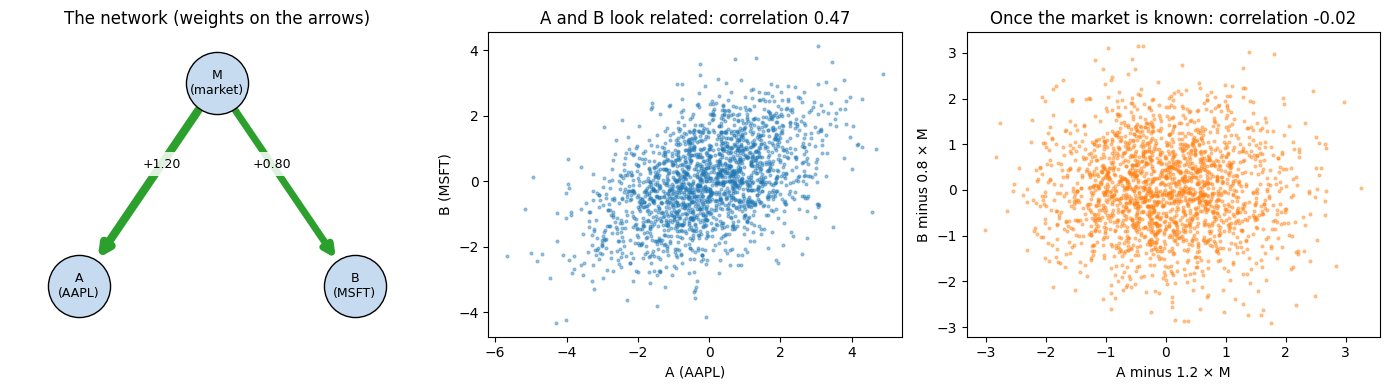

In [2]:
n = 2000
M = rng.normal(0, 1, n)
A = 1.2 * M + rng.normal(0, 1, n)
B = 0.8 * M + rng.normal(0, 1, n)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
draw_small(axes[0], {"M\n(market)": (0.5, 1), "A\n(AAPL)": (0, 0), "B\n(MSFT)": (1, 0)},
           [("M\n(market)", "A\n(AAPL)", 1.2), ("M\n(market)", "B\n(MSFT)", 0.8)], "The network (weights on the arrows)")
axes[1].scatter(A, B, s=4, alpha=0.4)
axes[1].set_xlabel("A (AAPL)"); axes[1].set_ylabel("B (MSFT)")
axes[1].set_title(f"A and B look related: correlation {np.corrcoef(A, B)[0, 1]:.2f}")
rA, rB = A - 1.2 * M, B - 0.8 * M                       # what is left after removing the market
axes[2].scatter(rA, rB, s=4, alpha=0.4, color="C1")
axes[2].set_xlabel("A minus 1.2 × M"); axes[2].set_ylabel("B minus 0.8 × M")
axes[2].set_title(f"Once the market is known: correlation {np.corrcoef(rA, rB)[0, 1]:.2f}")
plt.tight_layout(); plt.show()

**The key idea of a Bayesian network: conditional independence.**

- Middle plot: AAPL and MSFT clearly move together.
- Right plot: once the market's effect is removed, the relationship disappears. They only moved together **because both listen to the market.**

The graph shows this with a **missing arrow**: no arrow between A and B means "no direct link once the parents are known". In the GDBN, most arrows are missing on purpose, and each missing arrow is a statement of this kind. (In Koller & Friedman's language: the path A ← M → B is **blocked** when M is observed. This is d-separation, Ch. 3.)

---
## Part 2. Learning the weights when the arrows are known

Suppose we know the arrows (M → A, M → B) but not the weights. Two facts make learning easy:

1. **Each node is learned on its own.** The network's total fit is a sum of one piece per node, so learning A's rule never affects B's rule. Koller & Friedman call this **decomposability** (Ch. 17–18).
2. **For a Gaussian rule, learning the weight is a regression.** The most likely weight (the *maximum likelihood* estimate) is the one that makes the squared errors smallest:

$$\hat w = \arg\min_w \sum_{t} \big(A_t - w\,M_t\big)^2 \qquad\Longrightarrow\qquad \hat w = \frac{\sum_t A_t M_t}{\sum_t M_t^2}$$

The noise size $\sigma$ is then just the standard deviation of what is left over (the residuals).

More data gives better estimates:

In [3]:
rows = []
for T in [20, 100, 500, 2000]:
    wA = (A[:T] @ M[:T]) / (M[:T] @ M[:T])
    wB = (B[:T] @ M[:T]) / (M[:T] @ M[:T])
    rows.append({"days of data": T, "learned weight M→A (true 1.2)": wA, "learned weight M→B (true 0.8)": wB,
                 "learned noise sd of A (true 1.0)": np.std(A[:T] - wA * M[:T])})
pd.DataFrame(rows).set_index("days of data").round(3)

,learned weight M→A (true 1.2),learned weight M→B (true 0.8),learned noise sd of A (true 1.0)
days of data,,,
20,1.118,0.632,0.950
100,1.257,0.534,1.004
500,1.218,0.782,0.986
2000,1.183,0.792,0.996


---
## Part 3. Adding time, and finding the arrows (lasso)

### 3.1 The dynamic (temporal) Bayesian network

For prediction, the question is not "how are stocks related **today**?" but **"does what happened yesterday help predict today?"**

So each quantity appears **twice**: once for yesterday ($t-1$) and once for today ($t$). **Arrows only go from yesterday to today.** This is the "dynamic" in Dynamic Bayesian Network (Koller & Friedman, Ch. 6.2). Laid out over many days, the **same arrows repeat every day**:

```
   day t-2          day t-1           day t
  AAPL ───────┐    AAPL ───────┐    AAPL
              ├──►             ├──►
  MSFT ───────┘    MSFT ───────┘    MSFT        (same arrows, same weights, every day)
```

Three assumptions, in plain words:

| Assumption | Meaning | How the thesis model handles it |
|---|---|---|
| **Markov (one lag)** | Only yesterday is needed to predict today | To use a longer memory, add nodes that summarize the past (past-week and past-month averages, notebook 10) |
| **Same rules every day** | The weights do not change within the training window | The network is **re-learned every quarter** on the past 3 years (Part 5), so it can change over time |
| **No arrows within a day** | Today's values are predicted only from yesterday's | Every input is known at yesterday's close: no look-ahead |

Because arrows only point forward in time, **a loop is impossible**. So any set of arrows is a valid network, and each of today's nodes can be learned on its own (Part 2).

### 3.2 The equation: a VAR(1)

Stack all the variables into one list $x_t$. The whole network is one line:

$$x_t = A\, x_{t-1} + \varepsilon_t$$

- $A$ is a table of weights. $A_{ij}$ is the weight on the arrow from variable $j$ yesterday to variable $i$ today.
- **$A_{ij} = 0$ means there is no arrow.**
- Economists call this a **VAR(1)** (vector autoregression with one lag). A **sparse** VAR(1) is one where most of $A$ is zero: a GDBN with only a few arrows.

### 3.3 Finding the arrows: the lasso

We don't know which arrows exist. So each of today's nodes gets **all** of yesterday's nodes as candidate parents, and we use the **lasso**:

$$\min_{w}\;\; \underbrace{\frac{1}{2n}\sum_t \Big(y_t - \sum_j w_j\, x_{j,t-1}\Big)^2}_{\text{how badly the rule fits}} \;+\; \underbrace{\lambda \sum_j |w_j|}_{\text{a price for every arrow}}$$

- The first part wants a good fit. The second part charges a price $\lambda$ for every unit of weight.
- An arrow that only helps a little is **not worth its price**, and its weight becomes **exactly 0**. That arrow is removed.
- **$\lambda$ is the price.** Large λ means few arrows. Small λ means many arrows.

So the lasso learns the **arrows** (structure) and their **weights** (parameters) at the same time.

**The Bayesian view.** The lasso answer is the *most probable* set of weights if, before seeing any data, you believe each weight is probably close to zero (a "Laplace prior"). λ says how strongly you believe that. This is called a MAP estimate (Koller & Friedman, Ch. 17 and 20).

### 3.4 Example: can the lasso find a known network?

Below we make up a 5-variable network with 6 true arrows, simulate 3 years (756 days), and ask the lasso to find the arrows using **three different λ values**.

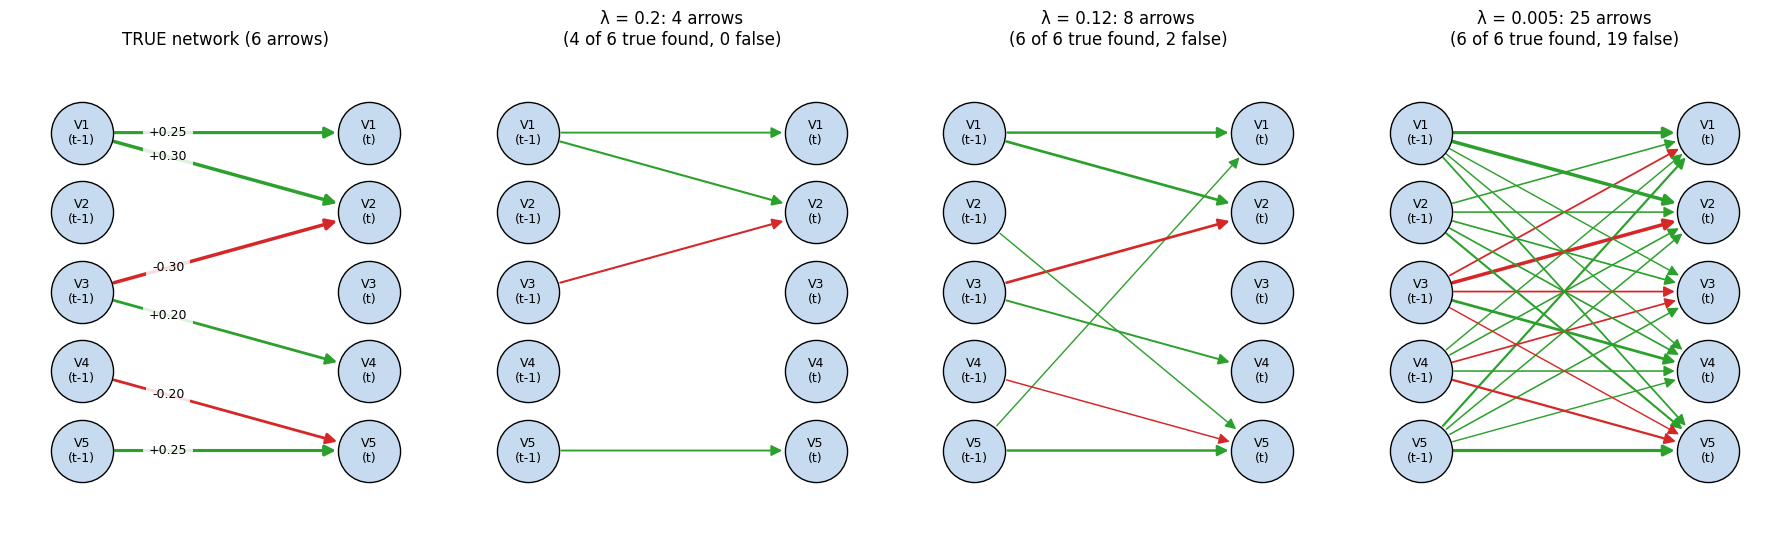

In [4]:
names = ["V1", "V2", "V3", "V4", "V5"]
A_true = np.zeros((5, 5))                    # A_true[i, j] = arrow from j (yesterday) to i (today)
A_true[0, 0], A_true[1, 0], A_true[1, 2], A_true[3, 2], A_true[4, 3], A_true[4, 4] = 0.25, 0.3, -0.3, 0.2, -0.2, 0.25
T = 756
x = np.zeros((T, 5))
for t in range(1, T):
    x[t] = A_true @ x[t - 1] + rng.normal(0, 1, 5)

def learn(x, alphas):
    # One lasso per variable (today) on all variables (yesterday); returns weights[λ, i, j]
    X, Y = x[:-1], x[1:]
    Xz = (X - X.mean(0)) / X.std(0)
    out = np.zeros((len(alphas), 5, 5))
    for i in range(5):
        y = (Y[:, i] - Y[:, i].mean()) / Y[:, i].std()
        _, coefs, _ = lasso_path(Xz, y, alphas=alphas)
        out[:, i, :] = coefs.T
    return out

lams = np.array([0.2, 0.12, 0.005])
learned = learn(x, lams)

def two_slice(W, thr=0):
    pos = {**{f"{v}\n(t-1)": (0, -k) for k, v in enumerate(names)}, **{f"{v}\n(t)": (1, -k) for k, v in enumerate(names)}}
    edges = [(f"{names[j]}\n(t-1)", f"{names[i]}\n(t)", W[i, j]) for i in range(5) for j in range(5) if abs(W[i, j]) > thr]
    return pos, edges

fig, axes = plt.subplots(1, 4, figsize=(18, 5.5))
draw_small(axes[0], *two_slice(A_true), title="TRUE network (6 arrows)", at=0.3)
for ax, lam, W in zip(axes[1:], lams, learned):
    found = W != 0
    hit = (found & (A_true != 0)).sum()
    draw_small(ax, *two_slice(W), show_w=False,
               title=f"λ = {lam}: {found.sum()} arrows\n({hit} of 6 true found, {found.sum() - hit} false)")
plt.tight_layout(); plt.show()

- **λ too large:** the price is too high, and some real arrows are dropped.
- **λ in the middle:** all the true arrows are found, with only a couple of false ones.
- **λ too small:** nearly free arrows, so many **false arrows** appear. These are random patterns in this particular sample, and they will not repeat in the future (overfitting).

Choosing λ well matters. With real data we don't know the truth, so we choose λ by **how well the predictions work on data the network has not seen** (Part 5).

The plot below follows each weight as λ gets smaller (left to right). This is the **lasso path**. Arrows "switch on" one at a time. The strongest true arrows switch on first.

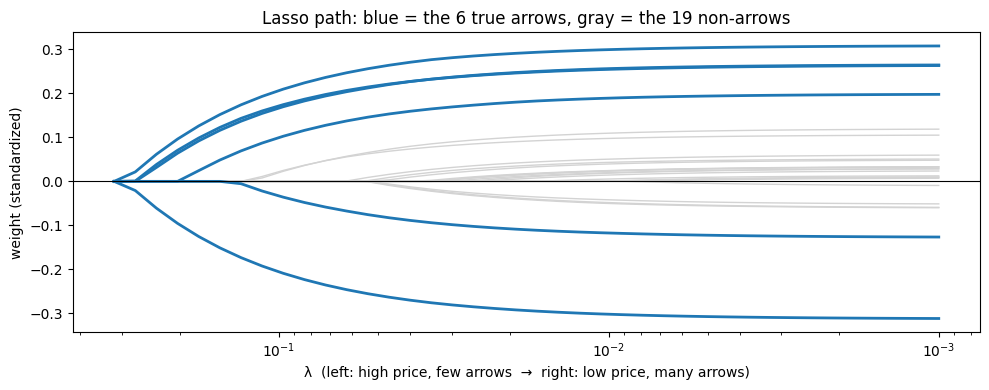

In [5]:
grid = np.logspace(-0.5, -3, 40)
path = learn(x, grid)
fig, ax = plt.subplots(figsize=(10, 4))
for i in range(5):
    for j in range(5):
        ax.semilogx(grid, path[:, i, j], color="C0" if A_true[i, j] != 0 else "lightgray", lw=2 if A_true[i, j] != 0 else 1)
ax.invert_xaxis(); ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("λ  (left: high price, few arrows  →  right: low price, many arrows)")
ax.set_ylabel("weight (standardized)")
ax.set_title("Lasso path: blue = the 6 true arrows, gray = the 19 non-arrows"); plt.tight_layout(); plt.show()

---
## Part 4. Real data: building one quarter's network, step by step

From here on, everything is real data and follows `pit_common.walk_forward` line by line. We take **one quarter**, the one starting **2 January 2019**, and build its network.

### 4.1 The universe (which stocks)

The universe is **point-in-time**: it only uses information available on the first trading day of the quarter. It is not chosen with hindsight.

| | Rule |
|---|---|
| **Full model** | the 5 largest S&P 500 members in each of the 11 sectors (about 52 stocks), by market cap on the previous day |
| **This walkthrough** | the largest stock in each sector, then the 10 largest of those (10 stocks from 10 different sectors) |

Both are taken from the same `universe.csv`, re-selected every quarter.

In [6]:
D = pc.load()                                                     # same data as the full model (nothing after 2022)
sel = pd.read_csv(pc.BUILT / "universe.csv", parse_dates=["rebalance_date"]).query("selected")
TK = dict(zip(sel["permno"], sel["ticker"]))

def ten_leaders(g):
    return g.sort_values("cap", ascending=False).drop_duplicates("sector").head(10)

U10 = {r: list(ten_leaders(g)["permno"]) for r, g in sel.groupby("rebalance_date") if r in D.U}
D10 = SimpleNamespace(**{**vars(D), "U": U10})                  # the full model's data, with the 10-stock universe

r = pd.Timestamp("2019-01-02")
U = U10[r]
print(f"Quarter starting {r.date()}: universe of {len(U)} stocks (full model that quarter: {len(D.U[r])} stocks)")
ten_leaders(sel[sel["rebalance_date"] == r])[["ticker", "sector_name", "cap"]].assign(
    cap=lambda d: (d["cap"] / 1e6).round(0).astype(int).astype(str) + " bn").rename(
    columns={"sector_name": "sector", "cap": "market cap (previous day)"}).reset_index(drop=True)

Quarter starting 2019-01-02: universe of 10 stocks (full model that quarter: 55 stocks)


,ticker,sector,market cap (previous day)
0,MSFT,Information Technology,780 bn
1,AMZN,Consumer Discretionary,734 bn
2,GOOG,Communication Services,362 bn
3,JNJ,Health Care,346 bn
4,JPM,Financials,325 bn
5,XOM,Energy,289 bn
6,WMT,Consumer Staples,271 bn
7,BA,Industrials,183 bn
8,NEE,Utilities,83 bn
9,AMT,Real Estate,70 bn


### 4.2 The nodes

| | Nodes | Count (10 stocks) |
|---|---|---|
| **Yesterday ($t-1$)** | each stock's **excess return**, news **sentiment**, news **attention**, plus 5 ETF returns (SPY, USO, GLD, DBC, TLT) | 10 × 3 + 5 = **35** |
| **Today ($t$)** | each stock's **excess return** (what we predict) | **10** |

- **Excess return** = the stock's return minus the average return of the universe that day. This removes "the whole market went up", which affects every stock equally, and keeps what matters for **ranking**: did this stock beat the others?
- **Sentiment** = the average RavenPack news sentiment that day. **Attention** = log(1 + number of news stories).
- The ETFs are market-wide nodes: they can influence the stocks, but we don't predict them.

The code below builds the table of inputs exactly as `walk_forward` does. The key line is `.shift(1)`: the row for day $t$ holds **day $t-1$'s values**, so a prediction for day $t$ can only use what was known at yesterday's close.

In [7]:
pos = D.days.searchsorted(r)
nxt = D.rebal[D.rebal.index(r) + 1]                                     # the next quarter starts here
hold = D.days[pos: D.days.searchsorted(nxt)]                             # the quarter we predict
win = D.days[pos - pc.WINDOW: pos]                                        # training window: the 756 days before it
span = D.days[pos - pc.WINDOW - pc.LOOKBACK: pos + len(hold)]

R = D.RET.reindex(index=span, columns=U)
EX = R.sub(R.mean(axis=1), axis=0)                                        # excess return vs the universe average
X = pc.daily_features(D, span, U, EX).shift(1)                            # inputs: information through day t-1
Y = EX                                                                    # target: today's excess return

def label(c):
    p, _, kind = c.partition("|")
    return f"{TK[int(p)]} {kind}" if kind else f"{c} (ETF)"
kind_of = lambda c: c.split("|")[1] if "|" in c else "etf"

msft = [p for p in U if TK[p] == "MSFT"][0]
d3 = hold[:3]
print("How the excess return is made (MSFT, first 3 days of the quarter):")
print(pd.DataFrame({"MSFT return": R.loc[d3, msft], "universe average": R.loc[d3].mean(axis=1),
                    "MSFT excess return (target)": EX.loc[d3, msft]}).round(4).to_string(), "\n")
print("The shift: the input row for each day holds the PREVIOUS day's value")
print(pd.DataFrame({"MSFT excess return that day": EX.loc[hold[:4], msft],
                    "input 'MSFT ret' on that row": X.loc[hold[:4], f"{msft}|ret"]}).round(4).to_string(), "\n")
print(f"Training window: {win[0].date()} to {win[-1].date()} ({len(win)} days); "
      f"quarter predicted: {hold[0].date()} to {hold[-1].date()} ({len(hold)} days)")
print(f"Input table: {X.shape[1]} columns (yesterday's nodes): " + ", ".join(label(c) for c in X.columns[:6]) + ", ...")

How the excess return is made (MSFT, first 3 days of the quarter):
            MSFT return  universe average  MSFT excess return (target)
date                                                                  
2019-01-02      -0.0044            0.0033                      -0.0078
2019-01-03      -0.0368           -0.0177                      -0.0191
2019-01-04       0.0465            0.0322                       0.0144 

The shift: the input row for each day holds the PREVIOUS day's value
            MSFT excess return that day  input 'MSFT ret' on that row
date                                                                 
2019-01-02                      -0.0078                        0.0036
2019-01-03                      -0.0191                       -0.0078
2019-01-04                       0.0144                       -0.0191
2019-01-07                      -0.0040                        0.0144 

Training window: 2015-12-30 to 2018-12-31 (756 days); quarter predicted: 2019-01-02 t

### 4.3 The training window

The network for this quarter learns only from the **756 trading days (3 years) before the quarter starts**. Then it is frozen and used for every day of the quarter. Nothing from the quarter itself is used for learning.

### 4.4 Standardizing (z-scores)

Inputs are measured in different units: a return is about 0.01, an attention value about 3. Each input is turned into a **z-score**:

$$z = \frac{\text{value} - \text{window average}}{\text{window standard deviation}}$$

so every input is in "standard deviations from normal". The average and standard deviation come **only from the training window** (no peeking at the quarter). A missing value (for example, sentiment on a day with no news) becomes 0, which means "average".

The target is standardized the same way, using the stock's own standard deviation $s_y$. At prediction time the score is multiplied back by $s_y$ to get returns.

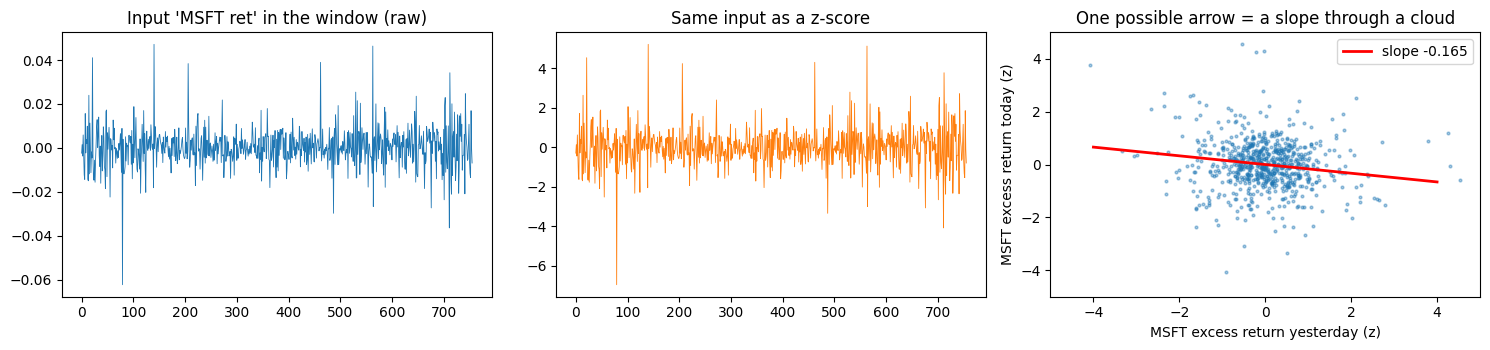

In [8]:
Xw, Xh = X.loc[win], X.loc[hold]
mu, sd = Xw.mean(), Xw.std().replace(0, np.nan)
Xwz, Xhz = ((Xw - mu) / sd).fillna(0).values, ((Xh - mu) / sd).fillna(0).values
xm = Xwz.mean(axis=0)                                                     # window average of each z-score (about 0)

c = f"{msft}|ret"
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].plot(Xw[c].values, lw=0.6); axes[0].set_title("Input 'MSFT ret' in the window (raw)")
axes[1].plot(Xwz[:, list(X.columns).index(c)], lw=0.6, color="C1"); axes[1].set_title("Same input as a z-score")
zprev, ytoday = Xwz[:, list(X.columns).index(c)], (EX.loc[win, msft] - EX.loc[win, msft].mean()) / EX.loc[win, msft].std()
axes[2].scatter(zprev, ytoday, s=4, alpha=0.4)
b = np.polyfit(zprev, ytoday, 1)
xx = np.linspace(-4, 4, 2); axes[2].plot(xx, np.polyval(b, xx), color="red", lw=2, label=f"slope {b[0]:+.3f}")
axes[2].set_xlim(-5, 5); axes[2].set_ylim(-5, 5); axes[2].legend()
axes[2].set_xlabel("MSFT excess return yesterday (z)"); axes[2].set_ylabel("MSFT excess return today (z)")
axes[2].set_title("One possible arrow = a slope through a cloud")
plt.tight_layout(); plt.show()

The right plot shows what **one arrow** is: the slope of a line through a cloud of (yesterday, today) points. The cloud is almost round. **Daily returns are mostly noise**, so true slopes are tiny. That is why the lasso is needed. With 35 candidate parents per stock, many small slopes would appear just by chance (as in Part 3, with λ too small).

### 4.5 One lasso per stock

This is the learning step. For each of the 10 stocks: today's excess return (standardized) is regressed on all 35 of yesterday's z-scores with the lasso, **for a whole grid of 20 λ values at once** (`lasso_path`). The code is exactly the loop inside `pit_common.walk_forward`:

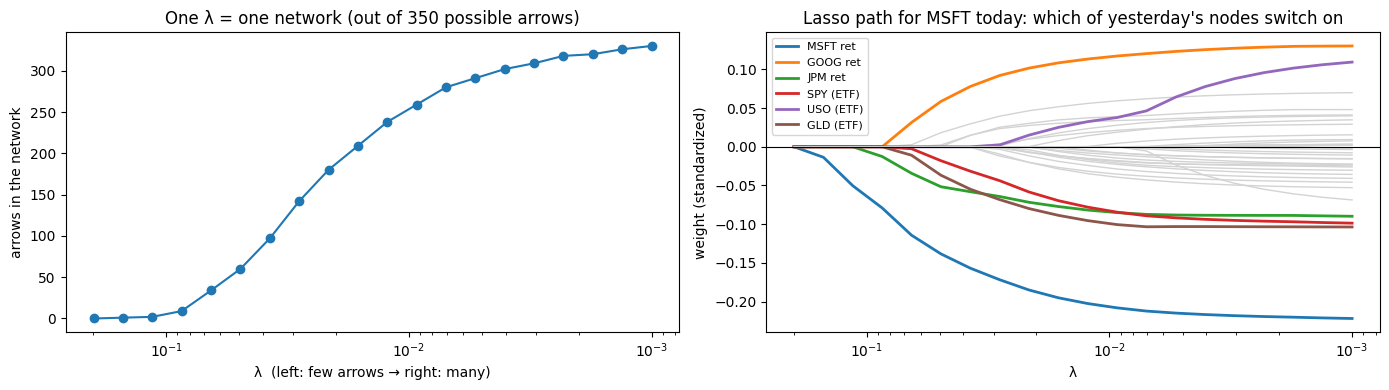

In [10]:
S = np.full((len(pc.ALPHAS), len(hold), len(U)), np.nan)    # predictions: [λ, day, stock]
W = np.zeros((len(U), X.shape[1], len(pc.ALPHAS)))          # weights: [stock (today), input (yesterday), λ]
ybar, ysd = np.zeros(len(U)), np.zeros(len(U))
for i, p in enumerate(U):
    y = Y.loc[win, p].values
    ok = ~np.isnan(y)
    if ok.sum() < 252:                                      # need at least 1 year of returns
        continue
    ys = y[ok].std()
    _, coefs, _ = lasso_path(Xwz[ok] - xm, (y[ok] - y[ok].mean()) / ys, alphas=pc.ALPHAS)
    W[i] = coefs                                            # the arrows into stock i, for every λ
    S[:, :, i] = ((Xhz - xm) @ coefs).T * ys                # the predictions for every day of the quarter
    ybar[i], ysd[i] = y[ok].mean(), ys

arrows = (W != 0).sum(axis=(0, 1))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].semilogx(pc.ALPHAS, arrows, "o-"); axes[0].invert_xaxis()
axes[0].set_xlabel("λ  (left: few arrows → right: many)"); axes[0].set_ylabel("arrows in the network")
axes[0].set_title(f"One λ = one network (out of {len(U) * X.shape[1]} possible arrows)")
i0 = U.index(msft)
top = np.argsort(-np.abs(W[i0]).max(axis=1))[:6]                # label the 6 strongest, the rest in gray
for j in range(X.shape[1]):
    if j in top:
        axes[1].semilogx(pc.ALPHAS, W[i0, j], lw=2, label=label(X.columns[j]))
    elif (W[i0, j] != 0).any():
        axes[1].semilogx(pc.ALPHAS, W[i0, j], color="lightgray", lw=1)
axes[1].invert_xaxis(); axes[1].axhline(0, color="black", lw=0.8); axes[1].legend(fontsize=8)
axes[1].set_xlabel("λ"); axes[1].set_ylabel("weight (standardized)")
axes[1].set_title("Lasso path for MSFT today: which of yesterday's nodes switch on")
plt.tight_layout(); plt.show()

### 4.6 Drawing the network

Each λ gives a different network. Below are three of them for this quarter. Read each picture as **yesterday (left) → today (right)**. Green arrows are positive weights and red arrows are negative. Thicker arrows are larger weights. Only yesterday's nodes with at least one arrow are drawn.

Node colors: blue = excess return, orange = sentiment, purple = attention, green = ETF.

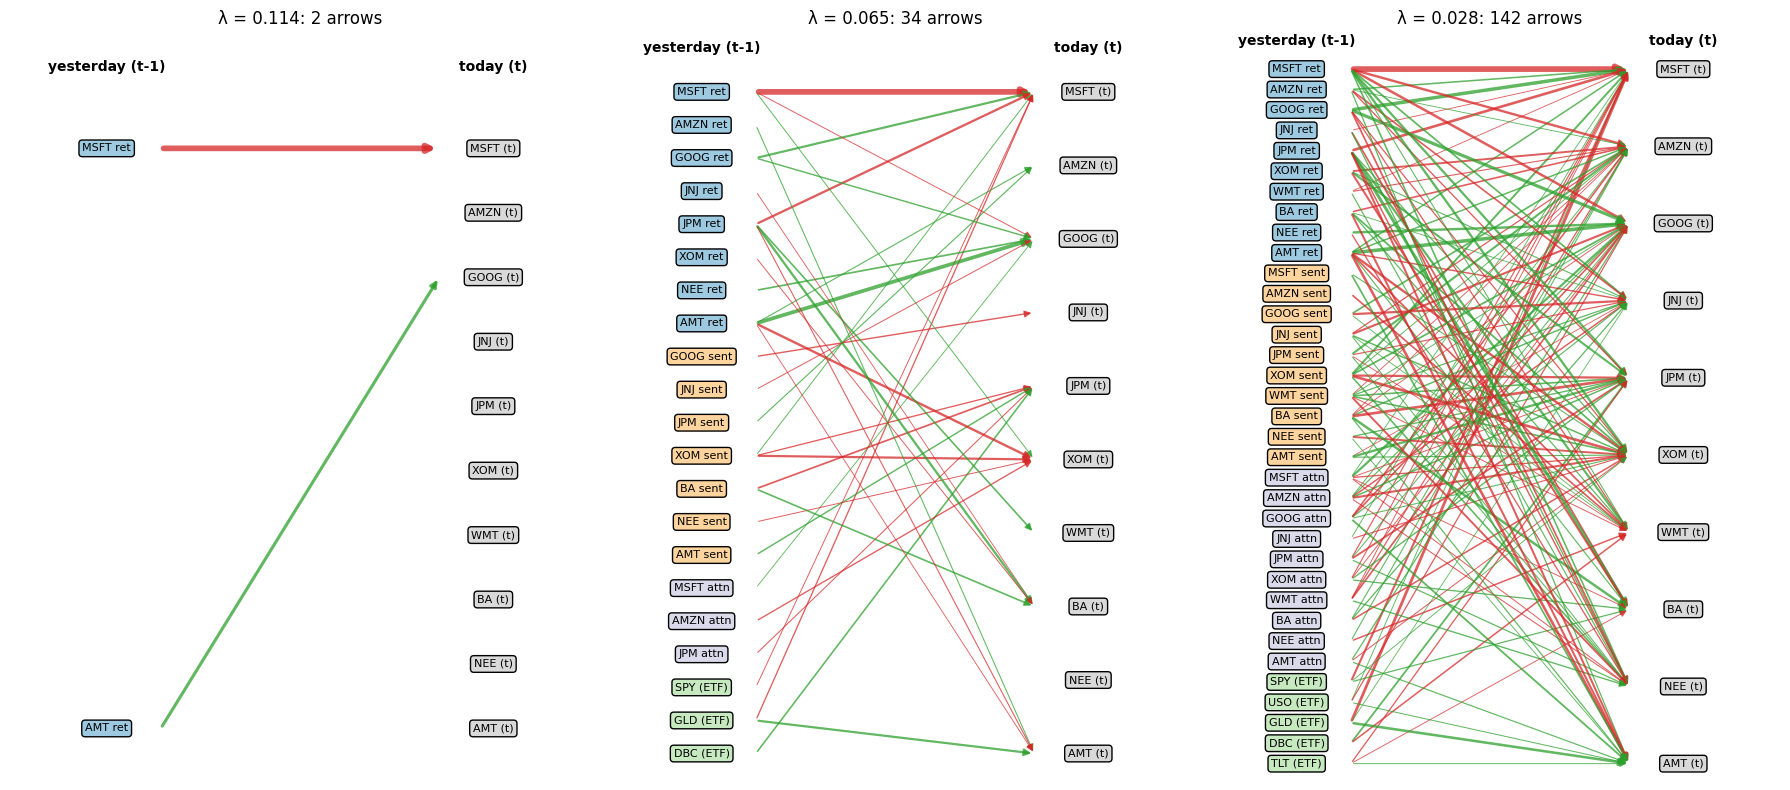

In [11]:
def draw_network(ax, Wk, cols, U, title=""):
    # Two-slice picture of one quarter's network at one λ: yesterday's nodes (left) -> today's excess returns (right)
    used = np.where((Wk != 0).any(axis=0))[0]
    H = max(len(used), len(U), 2)
    yl = {j: -k * (H - 1) / max(len(used) - 1, 1) for k, j in enumerate(used)}
    yr = {i: -i * (H - 1) / (len(U) - 1) for i in range(len(U))}
    wmax = np.abs(Wk).max() if len(used) else 1
    for i, j in zip(*np.nonzero(Wk)):
        ax.annotate("", xy=(0.86, yr[i]), xytext=(0.14, yl[j]),
                    arrowprops=dict(arrowstyle="-|>", color="tab:green" if Wk[i, j] > 0 else "tab:red",
                                    lw=0.6 + 3.5 * abs(Wk[i, j]) / wmax, alpha=0.75, mutation_scale=10))
    for j in used:
        ax.text(0, yl[j], label(cols[j]), ha="center", va="center", fontsize=8,
                bbox=dict(boxstyle="round", fc=TYPE_COLOR[kind_of(cols[j])]))
    for i in range(len(U)):
        ax.text(1, yr[i], f"{TK[U[i]]} (t)", ha="center", va="center", fontsize=8,
                bbox=dict(boxstyle="round", fc=TYPE_COLOR["today"]))
    ax.text(0, 1.2, "yesterday (t-1)", ha="center", weight="bold"); ax.text(1, 1.2, "today (t)", ha="center", weight="bold")
    ax.set_xlim(-0.25, 1.25); ax.set_ylim(-H + 0.2, 1.8); ax.axis("off"); ax.set_title(title)

show = [2, 4, 7]
fig, axes = plt.subplots(1, 3, figsize=(18, 8))
for ax, k in zip(axes, show):
    draw_network(ax, W[:, :, k], list(X.columns), U, f"λ = {pc.ALPHAS[k]:.3f}: {(W[:, :, k] != 0).sum()} arrows")
plt.tight_layout(); plt.show()

**How a learned network predicts.** Once the weights are learned, the prediction for a stock today is just the CPD's center: **the weighted sum of its parents' values yesterday**:

$$\text{score}_{i,t} = s_{y,i} \sum_{j \,\in\, \text{parents}(i)} w_{ij}\; z_{j,t-1}$$

A stock with no arrows gets a score of 0 ("no opinion"). Part 6 works through one prediction by hand. First we need to choose λ.

---
## Part 5. Through time: the walk-forward, and choosing λ

### 5.1 Re-learning every quarter

One network for all of 2006–2022 would assume the market never changes. Instead, the network is **re-learned at the start of every quarter**:

1. Pick the quarter's universe (point-in-time).
2. Learn the network on the **past 3 years only**.
3. Freeze it and predict every day of the quarter.
4. Move forward one quarter and repeat.

Every prediction is made by a network that **never saw that day**. These are **out-of-sample** predictions, as if the model had been run live at the time.

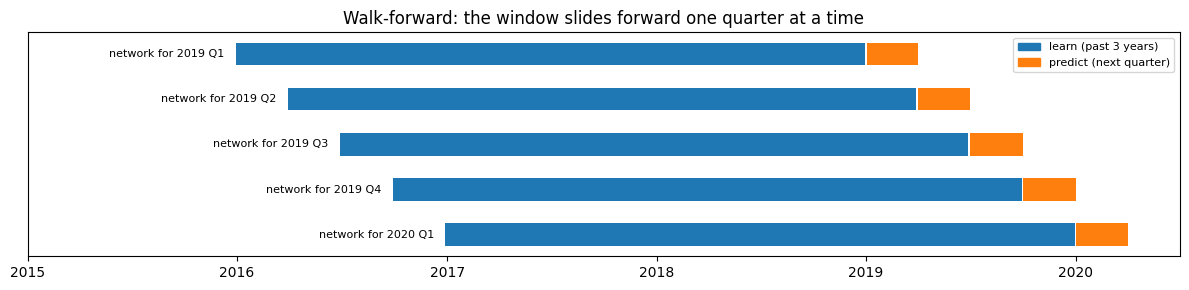

In [12]:
fig, ax = plt.subplots(figsize=(12, 3))
for k, rq in enumerate(D.rebal[52:57]):
    p0 = D.days.searchsorted(rq)
    nq = D.rebal[D.rebal.index(rq) + 1]
    ax.barh(k, D.days[p0 - 1] - D.days[p0 - pc.WINDOW], left=D.days[p0 - pc.WINDOW], color="C0", height=0.5)
    ax.barh(k, nq - rq, left=rq, color="C1", height=0.5)
    ax.text(D.days[p0 - pc.WINDOW] - pd.Timedelta(days=20), k, f"network for {rq.year} Q{(rq.month - 1) // 3 + 1}", fontsize=8, ha="right", va="center")
ax.set_xlim(pd.Timestamp("2015-01-01"), pd.Timestamp("2020-07-01"))
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="C0"), plt.Rectangle((0, 0), 1, 1, color="C1")],
          labels=["learn (past 3 years)", "predict (next quarter)"], loc="upper right", fontsize=8)
ax.invert_yaxis(); ax.set_yticks([])
ax.set_title("Walk-forward: the window slides forward one quarter at a time"); plt.tight_layout(); plt.show()

Now we run the full walk-forward for the 10-stock universe using **`pc.walk_forward`, the same function as the full model**. That is about 67 quarters × 10 lassos × 20 λ values, and takes a few seconds.

### 5.2 Choosing λ: rank IC

For each λ we now have out-of-sample predictions for every day in 2006–2022. We judge them by the **rank IC** (information coefficient):

- Each day, rank the stocks by **score** (prediction) and by **what actually happened** (excess return that day).
- The rank IC is the correlation between the two rankings: +1 means a perfect ranking, 0 means no skill, −1 means perfectly backwards.
- A daily rank IC of about **0.01–0.02 is normal** for real skill, because daily returns are mostly noise. It only adds up over thousands of days.

**One shared λ** is chosen: the one with the best average rank IC over **2006–2020**. Then 2021–2022 is used as a clean check (**validation**), with λ fixed. This is exactly `pc.choose_lambda`, as in the full model.

10-stock walk-forward: started
  10-stock walk-forward: 10 of 68 quarters (0s)
  10-stock walk-forward: 20 of 68 quarters (1s)
  10-stock walk-forward: 30 of 68 quarters (1s)
  10-stock walk-forward: 40 of 68 quarters (1s)
  10-stock walk-forward: 50 of 68 quarters (1s)
  10-stock walk-forward: 60 of 68 quarters (1s)
10-stock walk-forward: done in 1s


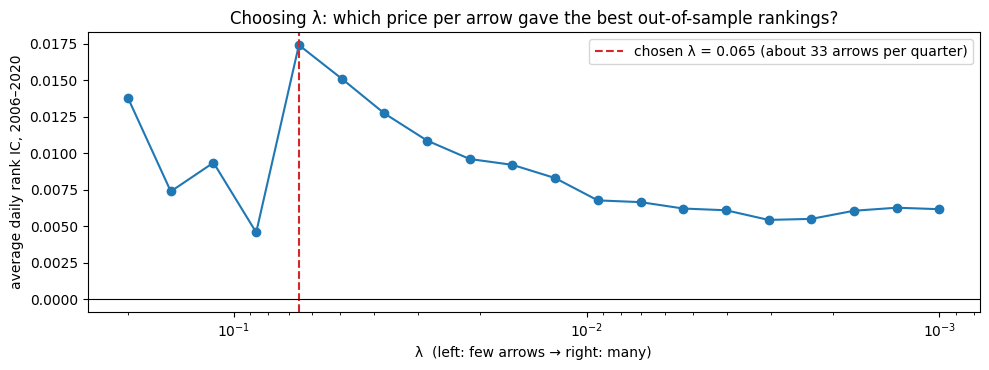

2006–2020 walk-forward: average rank IC 0.0174 (Newey-West t = 3.2, 3,695 days)
2021–2022 validation: average rank IC 0.0062 (Newey-West t = 0.4, 503 days)


In [13]:
res = pc.walk_forward(D10, pc.daily_features, label="10-stock walk-forward")
K, ics = pc.choose_lambda(D10, res, 1)
avg_arrows = [np.mean([(q["W"][:, :, k] != 0).sum() for q in res]) for k in range(len(pc.ALPHAS))]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.semilogx(pc.ALPHAS, ics, "o-")
ax.axvline(pc.ALPHAS[K], color="C3", ls="--", label=f"chosen λ = {pc.ALPHAS[K]:.3f} (about {avg_arrows[K]:.0f} arrows per quarter)")
ax.axhline(0, color="black", lw=0.8); ax.invert_xaxis(); ax.legend()
ax.set_xlabel("λ  (left: few arrows → right: many)"); ax.set_ylabel("average daily rank IC, 2006–2020")
ax.set_title("Choosing λ: which price per arrow gave the best out-of-sample rankings?")
plt.tight_layout(); plt.show()

score = pc.scores(res, K)                                     # date x stock table of predictions at the chosen λ
ic = pc.rank_ic(score, pc.forward_excess(D10, score, 1))
for name, (a, b) in pc.PERIODS.items():
    x_ = ic.loc[a:b]
    print(f"{name}: average rank IC {x_.mean():.4f} (Newey-West t = {pc.nw_t(x_):.1f}, {len(x_):,} days)")

- **Far left (huge λ):** almost no arrows, so almost every score is 0. The few non-zero scores come from a handful of quarters, so these points are very noisy (the jumpy part of the curve).
- **Far right (tiny λ):** hundreds of arrows, many of them false (Part 3), so the IC falls.
- **In between:** a few dozen arrows per quarter gives the best out-of-sample rankings.

With only 10 stocks the curve is bumpy. With about 52 stocks (notebook 06) there are many more rankings per day and it is smoother.

The **t-statistic** asks whether the average IC is clearly different from zero, given how noisy it is day to day. (Newey–West adjusts for days not being fully independent.) Roughly, |t| > 2 means "unlikely to be luck".

---
## Part 6. Making a prediction, by hand

Back to the quarter starting 2 January 2019, now at the chosen λ.

Chosen λ = 0.065: 34 arrows this quarter


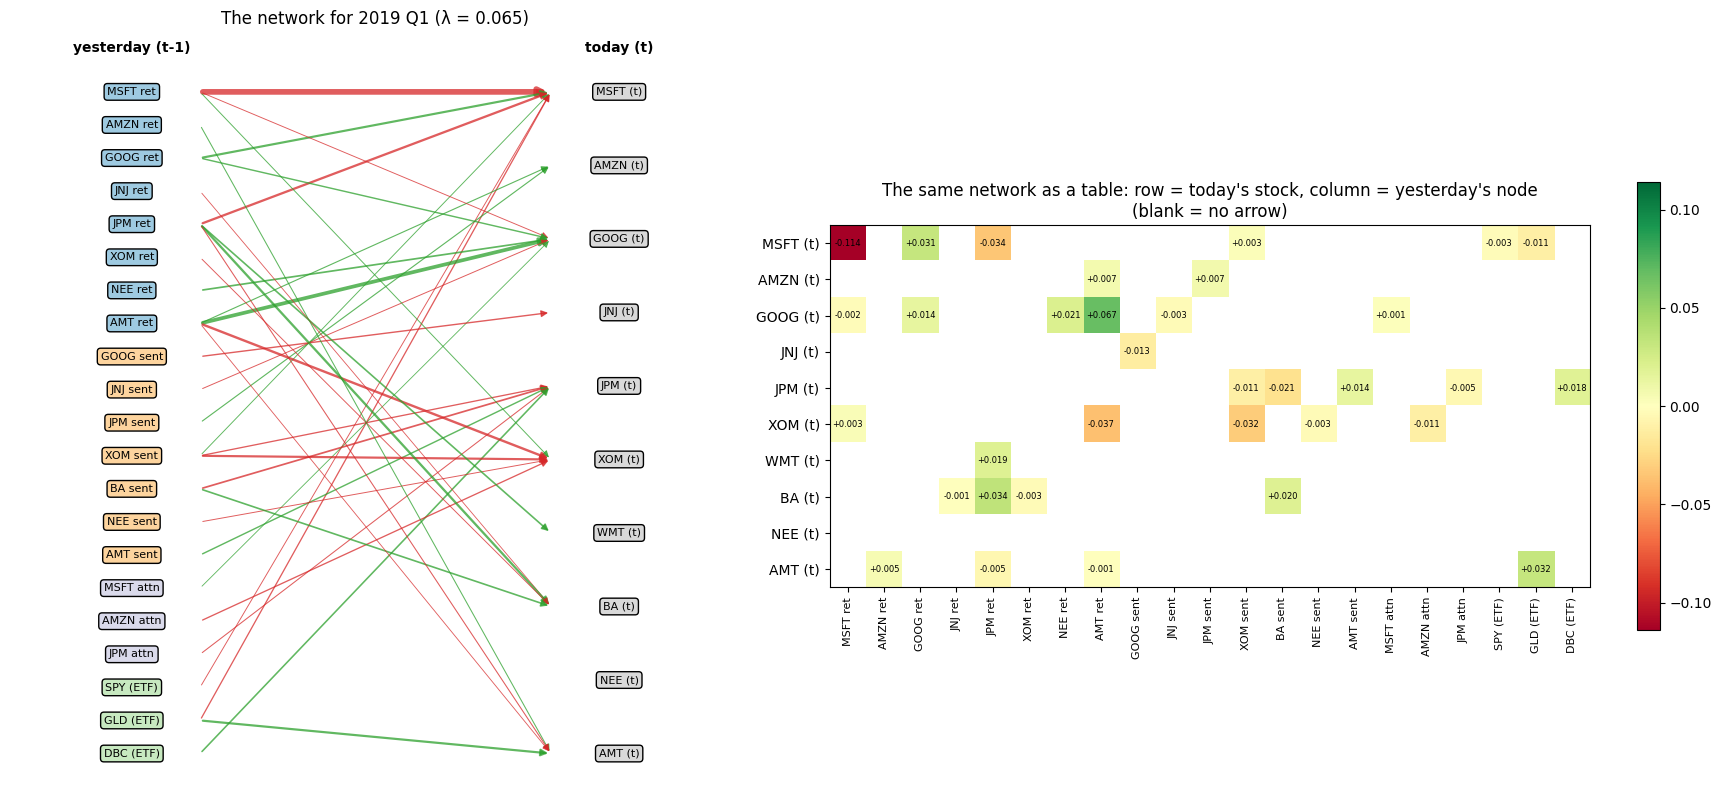

In [14]:
Wk = W[:, :, K]
print(f"Chosen λ = {pc.ALPHAS[K]:.3f}: {(Wk != 0).sum()} arrows this quarter")
fig, axes = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={"width_ratios": [1, 1.3]})
draw_network(axes[0], Wk, list(X.columns), U, f"The network for 2019 Q1 (λ = {pc.ALPHAS[K]:.3f})")
used = np.where((Wk != 0).any(axis=0))[0]
M_ = pd.DataFrame(Wk[:, used], index=[f"{TK[p]} (t)" for p in U], columns=[label(X.columns[j]) for j in used])
lim = np.abs(M_.values).max()
cmap = plt.get_cmap("RdYlGn").copy(); cmap.set_bad("white")
im = axes[1].imshow(np.ma.masked_equal(M_.values, 0), cmap=cmap, vmin=-lim, vmax=lim)
axes[1].set_xticks(range(len(used))); axes[1].set_xticklabels(M_.columns, rotation=90, fontsize=8)
axes[1].set_yticks(range(len(U))); axes[1].set_yticklabels(M_.index)
for (a, b), v in np.ndenumerate(M_.values):
    if v != 0:
        axes[1].text(b, a, f"{v:+.3f}", ha="center", va="center", fontsize=6)
axes[1].set_title("The same network as a table: row = today's stock, column = yesterday's node\n(blank = no arrow)")
plt.colorbar(im, ax=axes[1], shrink=0.6); plt.tight_layout(); plt.show()

The table on the right **is** the sparse VAR(1) matrix $A$ from Part 3 (only the columns with at least one arrow are shown). Every blank cell is a missing arrow: "no direct link from this node yesterday to this stock today, once the other inputs are known".

### 6.1 One stock, one day

We pick the stock with the most arrows into it, and the day in the quarter where its prediction is largest (a day where the network "has a strong opinion"). The prediction is the weighted sum of its parents' z-scores:

In [15]:
i = int(np.argmax((Wk != 0).sum(axis=1)))
p = U[i]
d = int(np.argmax(np.abs(S[K, :, i])))
day = hold[d]
par = np.where(Wk[i] != 0)[0]
cols = list(X.columns)
tab = pd.DataFrame({
    "parent (yesterday)": [label(cols[j]) for j in par],
    "raw value yesterday": [Xh.iloc[d, j] for j in par],
    "z-score": [Xhz[d, j] - xm[j] for j in par],
    "weight w": [Wk[i, j] for j in par],
})
tab["w × z"] = tab["weight w"] * tab["z-score"]
print(f"Predicting {TK[p]} on {day.date()}, using values from {D.days[D.days.searchsorted(day) - 1].date()}:\n")
print(tab.round(4).to_string(index=False))
by_hand = tab["w × z"].sum() * ysd[i]
print(f"\nsum of w × z                       = {tab['w × z'].sum():+.4f}  (in standard deviations)")
print(f"× {TK[p]}'s standard deviation s_y ({ysd[i]:.4f}) = {by_hand:+.5f}  → predicted excess return {by_hand * 1e4:+.1f} bps")
print(f"The model's score (from the loop above)  = {S[K, d, i]:+.5f}  ✓ same" if np.isclose(by_hand, S[K, d, i]) else "MISMATCH")
print(f"What actually happened that day: {TK[p]} excess return {EX.loc[day, p] * 1e4:+.1f} bps")

Predicting MSFT on 2019-02-01, using values from 2019-01-31:

parent (yesterday)  raw value yesterday  z-score  weight w   w × z
          MSFT ret              -0.0285  -3.1954   -0.1142  0.3650
          GOOG ret               0.0149   1.6725    0.0314  0.0526
           JPM ret              -0.0189  -1.7981   -0.0343  0.0616
          XOM sent               0.4467   1.4673    0.0027  0.0039
         SPY (ETF)               0.0088   1.0284   -0.0025 -0.0026
         GLD (ETF)               0.0005   0.0294   -0.0109 -0.0003

sum of w × z                       = +0.4802  (in standard deviations)
× MSFT's standard deviation s_y (0.0090) = +0.00432  → predicted excess return +43.2 bps
The model's score (from the loop above)  = +0.00432  ✓ same
What actually happened that day: MSFT excess return -95.2 bps


### 6.2 The prediction is a whole distribution (the "Bayesian" part)

The network does not just give one number. Its CPD for this stock is a **bell curve**:

$$\text{excess return}_{t} \mid \text{yesterday} \;\sim\; N\big(\bar y + \text{score}_t,\; \sigma^2\big)$$

- The **center** is the stock's average plus the score.
- The **width** $\sigma$ is the size of the errors in the training window.

The plot below compares it with the "no network" bell curve (just the average).

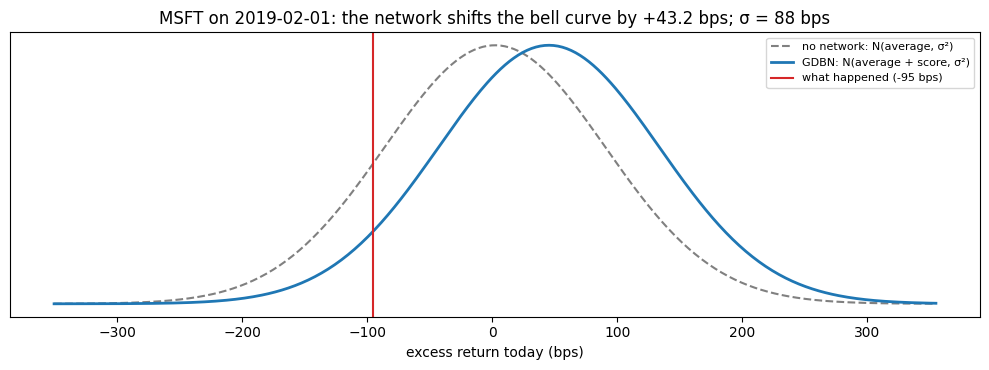

Shift / width on this day (the strongest of the quarter): 0.49
Shift / width on a typical day (median of the quarter):    0.07


In [16]:
y = Y.loc[win, p].values
ok = ~np.isnan(y)
fitted = ybar[i] + ((Xwz[ok] - xm) @ Wk[i]) * ysd[i]
sigma = np.std(y[ok] - fitted)
grid_ = np.linspace(-4 * sigma, 4 * sigma, 400) + ybar[i]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(grid_ * 1e4, norm.pdf(grid_, ybar[i], sigma), color="gray", ls="--", label="no network: N(average, σ²)")
ax.plot(grid_ * 1e4, norm.pdf(grid_, ybar[i] + S[K, d, i], sigma), color="C0", lw=2, label="GDBN: N(average + score, σ²)")
ax.axvline(EX.loc[day, p] * 1e4, color="C3", label=f"what happened ({EX.loc[day, p] * 1e4:+.0f} bps)")
ax.set_xlabel("excess return today (bps)"); ax.set_yticks([]); ax.legend(fontsize=8)
ax.set_title(f"{TK[p]} on {day.date()}: the network shifts the bell curve by {S[K, d, i] * 1e4:+.1f} bps; σ = {sigma * 1e4:.0f} bps")
plt.tight_layout(); plt.show()
print(f"Shift / width on this day (the strongest of the quarter): {abs(S[K, d, i]) / sigma:.2f}")
print(f"Shift / width on a typical day (median of the quarter):    {np.median(np.abs(S[K, :, i])) / sigma:.2f}")

This picture explains the whole project's numbers. **The network moves the center of the bell curve, but the curve stays wide.** Even on its strongest day, the actual return landed far from the center. On a typical day the shift is much smaller still. Most of a day's return is noise that nobody can predict. A small, consistent edge over thousands of stock-days is what a rank IC of 0.01–0.02 means.

The ranking uses only the **score** (the network's reaction to yesterday), not the stock's long-run average $\bar y$. The average is a noisy estimate from 3 years of data and is not something the network learned from yesterday's information.

### 6.3 From predictions to a ranking (one day)

Every stock gets a score each day. The stocks are ranked: **buy the top 20%** and **short the bottom 20%**. With 10 stocks that is 2 and 2; in the full model it is about 10 and 10. This is `pc.daily_portfolio`, the same function as the full model.

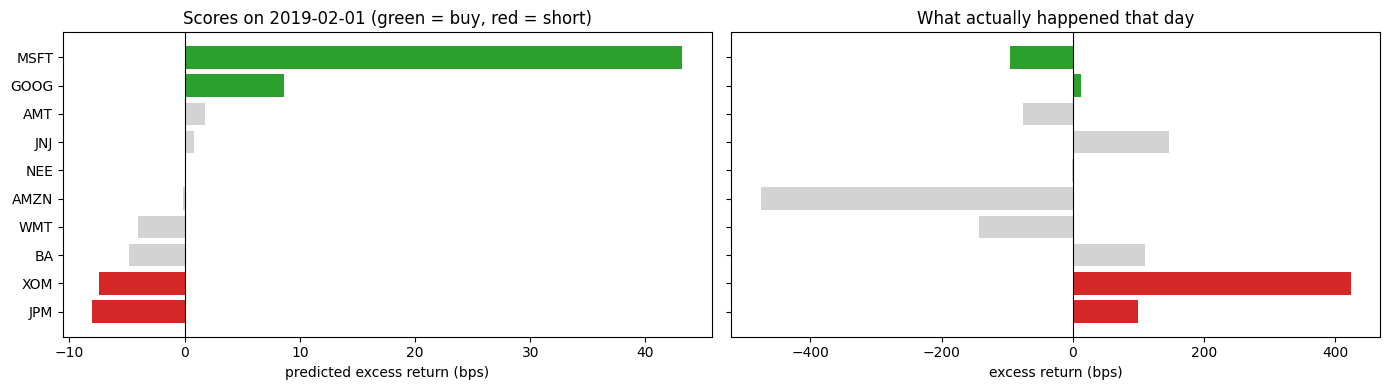

Rank IC that day = -0.36   |   long-short return that day = -302.7 bps


In [17]:
sday = pd.DataFrame(S[K], index=hold, columns=U)
wday = pc.daily_portfolio(sday).loc[day]
order = sday.loc[day].sort_values().index
actual = EX.loc[day, order]
colors = ["tab:green" if wday[q] > 0 else "tab:red" if wday[q] < 0 else "lightgray" for q in order]
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
axes[0].barh([TK[q] for q in order], sday.loc[day, order] * 1e4, color=colors)
axes[0].set_title(f"Scores on {day.date()} (green = buy, red = short)"); axes[0].set_xlabel("predicted excess return (bps)")
axes[1].barh([TK[q] for q in order], actual * 1e4, color=colors)
axes[1].set_title("What actually happened that day"); axes[1].set_xlabel("excess return (bps)")
for ax in axes:
    ax.axvline(0, color="black", lw=0.8)
plt.tight_layout(); plt.show()
rho = spearmanr(sday.loc[day], EX.loc[day, U]).correlation
print(f"Rank IC that day = {rho:+.2f}   |   long-short return that day = {(wday * D.RET.loc[day, U]).sum() * 1e4:+.1f} bps")

### 6.4 Over the whole quarter, and over all quarters

One day is luck either way. The daily rank ICs below jump between strongly positive and strongly negative. The edge, if there is one, is only visible in the **average** over many days.

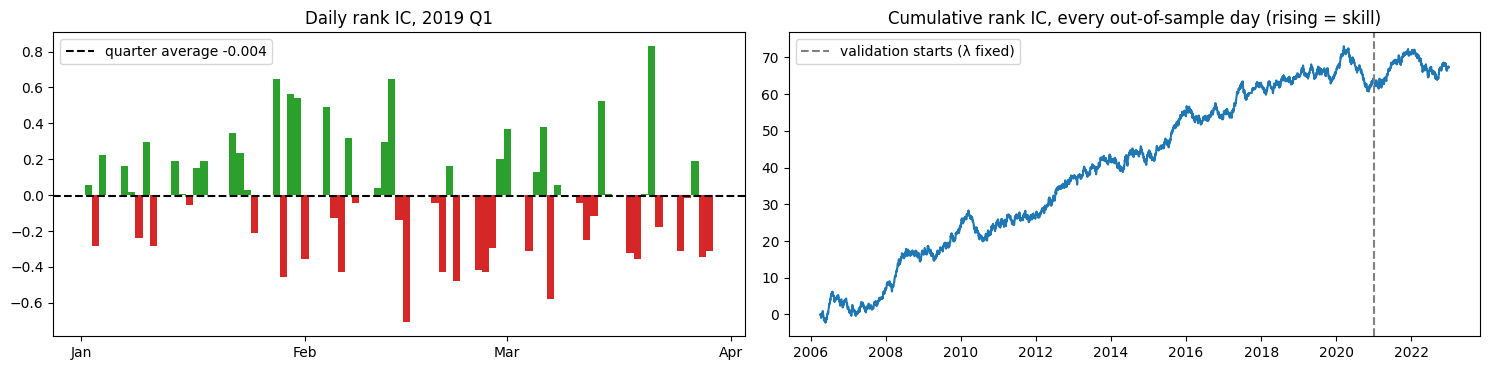

Long-short portfolio from the 10-stock scores (2 long, 2 short; cost 5 bps per unit traded):
                        bps/day      t  Sharpe gross  Sharpe net  turnover/day  breakeven bps
2006–2020 walk-forward    3.976  1.610         0.418      -1.066         2.825          1.407
2021–2022 validation     -0.055 -0.008        -0.006      -1.512         2.823         -0.019

With only 2 longs and 2 shorts this is very noisy. See notebook 06 for the full ~52-stock results.


In [18]:
q_ic = ic.loc[hold[0]:hold[-1]]
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
axes[0].bar(q_ic.index, q_ic.values, color=np.where(q_ic > 0, "tab:green", "tab:red"), width=1)
axes[0].axhline(q_ic.mean(), color="black", ls="--", label=f"quarter average {q_ic.mean():+.3f}")
axes[0].set_title("Daily rank IC, 2019 Q1"); axes[0].legend(); axes[0].xaxis.set_major_locator(mdates.MonthLocator()); axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
axes[1].plot(ic.cumsum())
axes[1].axvline(pd.Timestamp("2021-01-01"), color="gray", ls="--", label="validation starts (λ fixed)")
axes[1].set_title("Cumulative rank IC, every out-of-sample day (rising = skill)"); axes[1].legend()
plt.tight_layout(); plt.show()

w_ls = pc.held_weights(score, 1)
print("Long-short portfolio from the 10-stock scores (2 long, 2 short; cost 5 bps per unit traded):")
print(pd.DataFrame({name: pc.summary(D10, w_ls, a, b) for name, (a, b) in pc.PERIODS.items()}).T.round(3).to_string())
print("\nWith only 2 longs and 2 shorts this is very noisy. See notebook 06 for the full ~52-stock results.")

---
## Part 7. How the network changes over time

Because the network is re-learned every quarter, its arrows can appear, disappear, and change sign. This is the **temporal** side of the model at a second level:

- **Within a quarter**, arrows link yesterday to today (the DBN).
- **Across quarters**, the network itself evolves.

(Making that evolution part of the model, instead of re-learning from scratch, is one thing the TBGNN can add.)

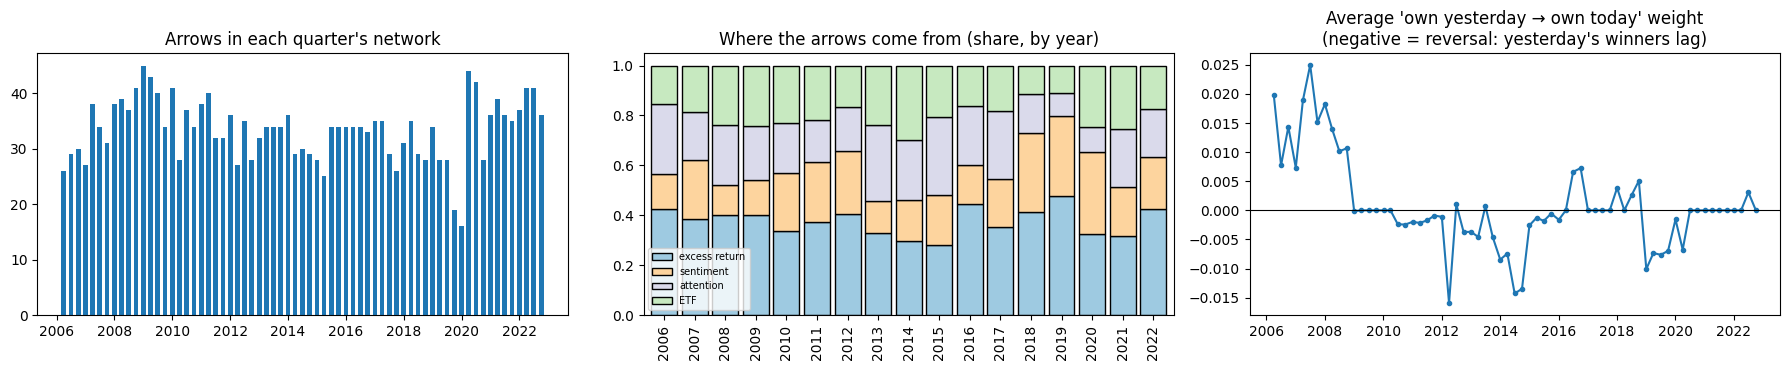

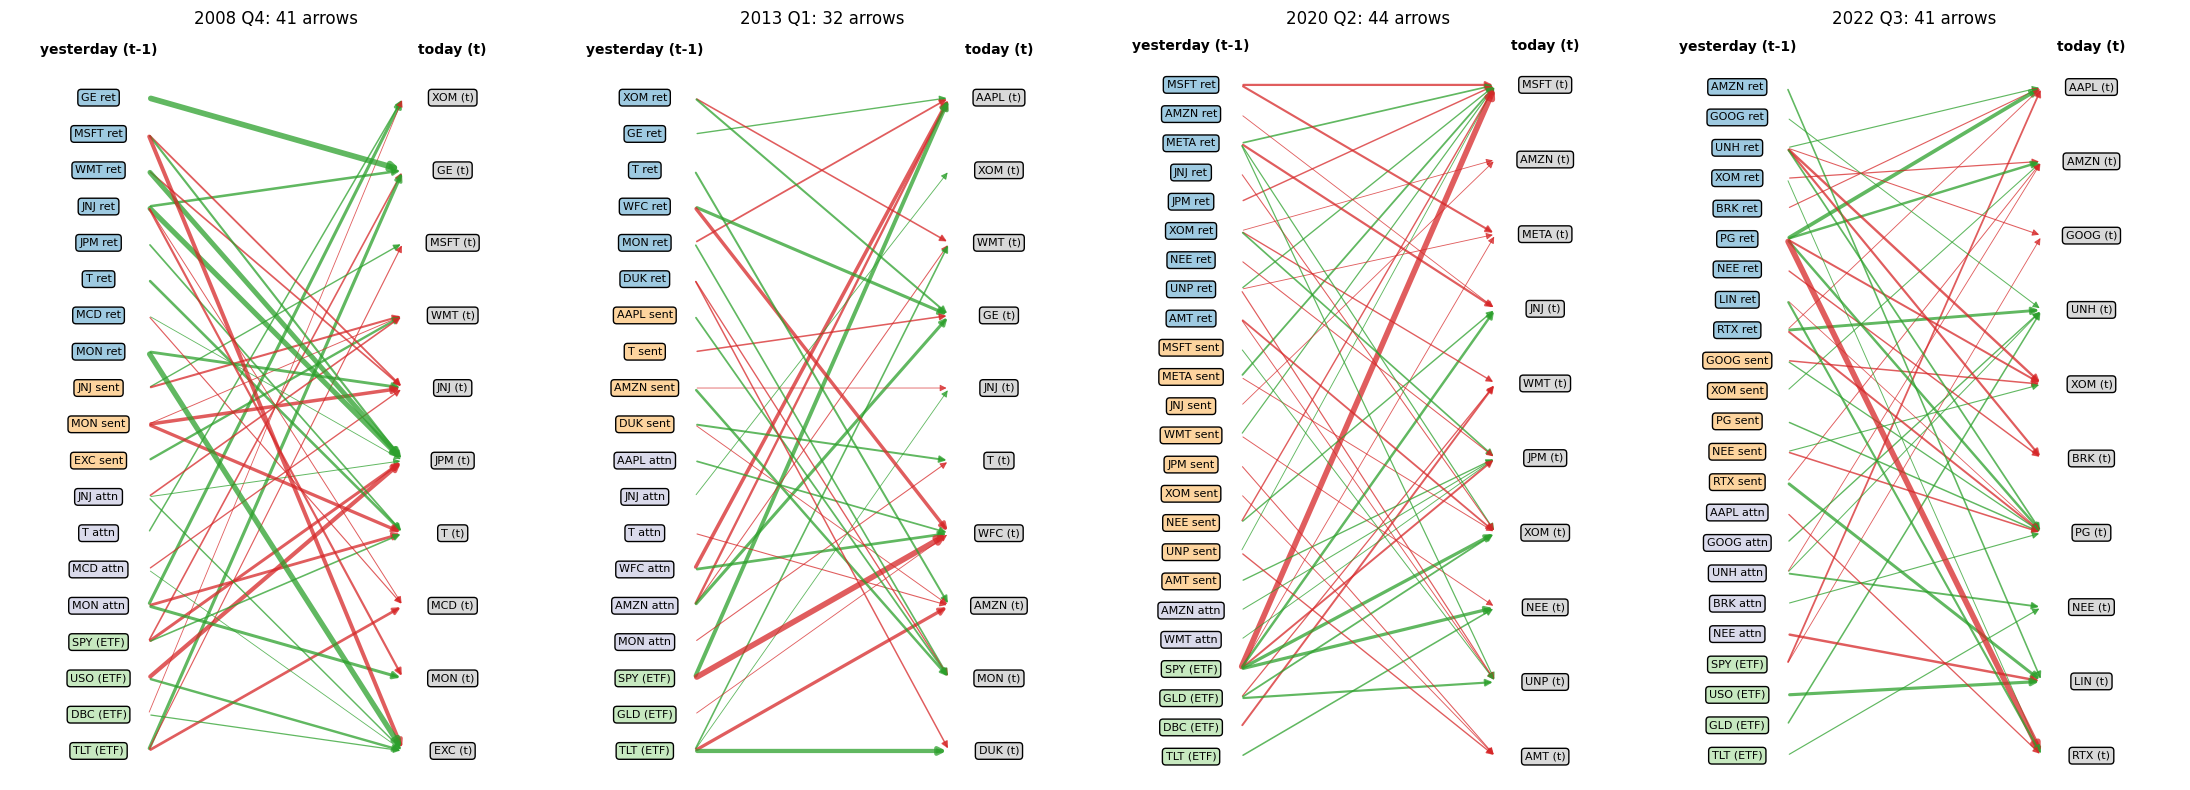

In [19]:
qdates = [q["r"] for q in res]
n_arrows = [(q["W"][:, :, K] != 0).sum() for q in res]
kinds = ["ret", "sent", "attn", "etf"]
share = pd.DataFrame([{kd: sum((q["W"][:, j, K] != 0).sum() for j, c in enumerate(q["cols"]) if kind_of(c) == kd) for kd in kinds}
                      for q in res], index=qdates)
self_w = [np.mean([q["W"][i, q["cols"].index(f"{p}|ret"), K] for i, p in enumerate(q["U"])]) for q in res]

fig, axes = plt.subplots(1, 3, figsize=(18, 3.8))
axes[0].bar(qdates, n_arrows, width=60); axes[0].set_title("Arrows in each quarter's network")
yr = share.groupby(share.index.year).sum()
(yr.div(yr.sum(axis=1), axis=0)).plot.bar(stacked=True, ax=axes[1], color=[TYPE_COLOR[k] for k in kinds], edgecolor="black", width=0.85)
axes[1].set_title("Where the arrows come from (share, by year)"); axes[1].legend(["excess return", "sentiment", "attention", "ETF"], fontsize=7)
axes[2].plot(qdates, self_w, "o-", ms=3); axes[2].axhline(0, color="black", lw=0.8)
axes[2].set_title("Average 'own yesterday → own today' weight\n(negative = reversal: yesterday's winners lag)")
plt.tight_layout(); plt.show()

picks = [pd.Timestamp(s) for s in ["2008-10-01", "2013-01-02", "2020-04-01", "2022-07-01"]]
fig, axes = plt.subplots(1, 4, figsize=(22, 8))
for ax, rq in zip(axes, picks):
    q = [q for q in res if q["r"] == rq][0]
    draw_network(ax, q["W"][:, :, K], q["cols"], q["U"], f"{rq.year} Q{(rq.month - 1) // 3 + 1}: {(q['W'][:, :, K] != 0).sum()} arrows")
plt.tight_layout(); plt.show()

Things to notice:

- **The number of arrows changes** from quarter to quarter (roughly 15 to 45 here), and so do the arrows themselves.
- **The universe changes too.** Stocks enter and leave as companies grow and shrink, so the nodes themselves change from quarter to quarter.
- **All four kinds of nodes are used.** Excess-return nodes give the largest share of arrows, but sentiment, attention, and ETF arrows appear every year.
- **Relationships can flip sign.** The "own yesterday → own today" weight was slightly positive in 2006–2008 (continuation) and has mostly been zero or negative since (reversal). A network learned once and kept forever would miss this.

---
## Part 8. Is this the same as the full model? What changes when it is scaled up?

**Check:** the step-by-step code in Part 4 should give exactly the same weights and predictions as `pc.walk_forward` for the 2019 Q1 quarter.

In [20]:
q = [q for q in res if q["r"] == r][0]
same_w = np.allclose(q["W"], W)
same_s = np.allclose(np.nan_to_num(q["S"]), np.nan_to_num(S))
print(f"Weights identical to pc.walk_forward:     {same_w}")
print(f"Predictions identical to pc.walk_forward: {same_s}")
print(f"\nFull model this quarter: {len(D.U[r])} stocks → {3 * len(D.U[r]) + 5} input nodes, "
      f"{len(D.U[r]) * (3 * len(D.U[r]) + 5):,} possible arrows (here: {len(U) * X.shape[1]})")

Weights identical to pc.walk_forward:     True
Predictions identical to pc.walk_forward: True

Full model this quarter: 55 stocks → 170 input nodes, 9,350 possible arrows (here: 350)


### What changes from this notebook to the full model (notebook 06)

| | This walkthrough | Full model |
|---|---|---|
| Universe each quarter | 10 sector leaders | 5 largest per sector (about 52) |
| Yesterday's nodes | 10 × 3 + 5 ETFs = 35 | about 52 × 3 + 5 = 161 |
| Today's nodes (lassos per quarter) | 10 | about 52 |
| Possible arrows | 350 | about 8,400 |
| Excess return measured against | the 10-stock average | the full universe average |
| Long / short each day | 2 / 2 | about 10 / 10 |
| Everything else (window, z-scores, lasso, λ grid, λ choice, walk-forward, ranking) | **identical code** | **identical code** |

Variants in later notebooks only **add nodes** (past-week and past-month averages in notebook 10, fundamentals in 11) or **change the target** (5- or 20-day returns in 09, volatility in 07). The way the network is built, learned, and used stays the same.

### Summary: the whole model in six lines

1. **Nodes:** yesterday's excess returns, sentiment, attention, and ETFs → today's excess returns.
2. **Rule for each node (CPD):** today = weighted sum of yesterday's parents + bell-curve noise (linear Gaussian).
3. **Arrows:** found by one lasso per stock. λ is the price per arrow, so most arrows are exactly 0 (sparse VAR(1)).
4. **λ:** the one with the best out-of-sample rank IC over 2006–2020, checked on 2021–2022.
5. **Through time:** re-learned every quarter on the past 3 years (walk-forward), so every prediction is out of sample.
6. **Prediction:** the center of the bell curve (weighted sum of parents' z-scores × $s_y$). Stocks are ranked by it: buy the top 20%, short the bottom 20%.

### Glossary

| Term | Meaning |
|---|---|
| Node | an uncertain quantity (one stock's return, sentiment, ...) |
| Arrow (edge) | "directly influences"; in the GDBN always from yesterday to today |
| Parent | a node with an arrow into another node |
| CPD | a node's rule: its distribution given its parents |
| Linear Gaussian CPD | weighted sum of parents + normal noise |
| DAG | a graph with arrows and no loops (every Bayesian network is one) |
| Conditional independence | once the parents are known, other nodes add nothing; shown by a missing arrow |
| DBN / two-slice network | the network copied for yesterday and today, with arrows between them |
| VAR(1) | the same model as an equation: today = A × yesterday + noise |
| Sparse | most weights (arrows) are exactly zero |
| Lasso, λ | regression with a price λ per unit of weight; sets weak weights to exactly 0 |
| z-score | (value − window average) / window standard deviation |
| Excess return | a stock's return minus the universe average that day |
| Walk-forward | re-learn every quarter on the past only; predict the next quarter |
| Rank IC | correlation between the predicted ranking and the actual ranking on a day |

### Where this is in Koller & Friedman

| Idea | Chapter |
|---|---|
| Graphs, factorization, conditional independence, d-separation | Ch. 3 |
| Linear Gaussian CPDs, Gaussian networks | Ch. 5.5, Ch. 7 |
| Dynamic Bayesian networks (two-slice templates) | Ch. 6.2 |
| Learning weights by maximum likelihood (and MAP / priors) | Ch. 17 |
| Learning the arrows (structure), decomposability | Ch. 18 |
| L1 (lasso) regularization for structure | Ch. 20 |